# Phase 2 – Notebook 5: Offline Rescheduling What-If

**Question:** if we trust the model's delay risk, could we reduce expected delays by moving risky flights to calmer departure hours?

This is a **simulation on past data**. No real flight is moved. It only shows how the model's probabilities could be used, under clear assumptions.

**Idea in simple words:**
1. The calibrated MLP gives every test flight a delay probability.
2. A flight with probability ≥ a **risk threshold** is "flagged".
3. For a flagged flight we try other departure hours (±2 hours, same day) and ask the model for the new risk.
4. We move the flight only if the risk drops by **more than a penalty** (moving has a cost).
5. We add up how many expected delays we avoided.

In [1]:
import sys, os, time
from pathlib import Path

# Work from the project root so imports and paths always work
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import Image, display

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)

metrics_dir = ROOT / "reports" / "metrics"
fig_dir = ROOT / "reports" / "figures"
metrics_dir.mkdir(parents=True, exist_ok=True)
fig_dir.mkdir(parents=True, exist_ok=True)


def to_md(df, digits=4):
    """Turn a DataFrame into a markdown table (used for the report)."""
    cols = list(df.columns)
    lines = ["| " + " | ".join(str(c) for c in cols) + " |",
             "|" + "|".join(["---"] * len(cols)) + "|"]
    for _, r in df.iterrows():
        cells = [f"{v:.{digits}f}" if isinstance(v, (float, np.floating)) else str(v) for v in r.values]
        lines.append("| " + " | ".join(cells) + " |")
    return "\n".join(lines) + "\n"


print("Project root:", ROOT)

Project root: /Users/atharvatiwari/Desktop/flight-delay-prediction


## 1. Assumptions (written down on purpose)
1. **Calibrated probability = real probability.** We treat the temperature-scaled MLP output as the true chance of delay. (Notebook 4 shows this is only approximately true.)
2. **Allowed moves:** same airport, same day, shift of ±1 or ±2 hours, new hour between 06:00 and 22:00.
3. **Only the hour features change** (`hour`, `hour_sin`, `hour_cos`). The history and congestion features of the new slot are **not** recomputed.
4. **Moving has a cost.** A move is allowed only if the risk drops by more than a penalty (0.05 in the main run, 0.03 and 0.08 in the sensitivity study).
5. **Capacity:** at most 5 moved flights can be added to the same airport-hour slot.
6. **The model's hour effect is treated as cause and effect.** This is the weakest assumption. The model learned that late hours are riskier, but this can come from delays piling up during the day, not from the hour itself. Moving a flight earlier would not necessarily give it the lower risk.
7. **Not modelled:** crews, gates, aircraft rotations, passengers, runway slots.

This is academic experimentation only. It is not an operational recommendation.

## 2. Load data and the saved MLP

In [2]:
from src.data_loader import load_data
from src.preprocessing import clean_data, create_target
from src.phase2_history_features import add_history_features, PHASE2_NUMERIC_FEATURES, PHASE2_FEATURE_COLUMNS

df_p2, _ = add_history_features(create_target(clean_data(load_data())), train_ratio=0.70)

n = len(df_p2)
train_end, val_end = int(n * 0.70), int(n * 0.85)
train_df = df_p2.iloc[:train_end].copy()
val_df   = df_p2.iloc[train_end:val_end].copy()
test_df  = df_p2.iloc[val_end:].copy()
y_train, y_val, y_test = train_df["delayed"].values, val_df["delayed"].values, test_df["delayed"].values

print(f"Train: {len(train_df):,} | Validation: {len(val_df):,} | Test: {len(test_df):,}")
print(f"Delay rate -> train {y_train.mean():.3f} | validation {y_val.mean():.3f} | test {y_test.mean():.3f}")

Train: 229,142 | Validation: 49,102 | Test: 49,102
Delay rate -> train 0.259 | validation 0.154 | test 0.267


In [3]:
import joblib
from src.dl_model import FlightMLP, build_tensors

saved = joblib.load(ROOT / "models" / "dl_artifacts.joblib")
cfg, mapper, scaler, num_cols = saved["config"], saved["mapper"], saved["scaler"], saved["numeric_cols"]

mlp = FlightMLP(
    num_carriers=mapper.num_classes("carrier"),
    num_origins=mapper.num_classes("origin"),
    num_dests=mapper.num_classes("dest"),
    num_numeric=len(num_cols),
    carrier_dim=cfg["carrier_dim"], origin_dim=cfg["origin_dim"],
    dest_dim=cfg["dest_dim"], dropout=cfg["dropout"],
)
mlp.load_state_dict(torch.load(ROOT / "models" / "dl_mlp_embeddings.pt"))
mlp.eval()   # important: switch off dropout, use BatchNorm in test mode
print("Loaded the saved MLP. Best epoch during training:", saved["best_epoch"])

Loaded the saved MLP. Best epoch during training: 3


## 3. Calibrated probabilities for the test flights
Temperature scaling is fitted on the validation set and applied to the test set (as in Notebook 4).

In [4]:
from src.phase2_calibration import TemperatureScaler

tensors_val  = build_tensors(val_df,  mapper, scaler, num_cols, is_train=False)
tensors_test = build_tensors(test_df, mapper, scaler, num_cols, is_train=False)

temp_scaler = TemperatureScaler().fit(mlp.predict_logits(*tensors_val), y_val)
test_probs_cal = temp_scaler.transform(mlp.predict_logits(*tensors_test))

print(f"Temperature T = {temp_scaler.temperature:.3f}")
print(f"Test flights: {len(test_df):,}")
print(f"Expected delayed flights (sum of probabilities): {test_probs_cal.sum():,.0f}")
print(f"Really delayed flights in the test set        : {int(y_test.sum()):,}")
for th in [0.35, 0.40, 0.45]:
    print(f"Flights with risk >= {th:.2f}: {(test_probs_cal >= th).sum():,}")

Temperature T = 0.570
Test flights: 49,102
Expected delayed flights (sum of probabilities): 10,070
Really delayed flights in the test set        : 13,106
Flights with risk >= 0.35: 8,478
Flights with risk >= 0.40: 6,454
Flights with risk >= 0.45: 4,939


## 4. Main simulation
Risk threshold **0.40**, penalty **0.05**.

This can take a few minutes, because for every flagged flight the model scores 2–4 other hours one by one. The sensitivity study below runs 6 more simulations, so the whole notebook may take 10–20 minutes. You can leave it running.

In [5]:
from src.phase2_rescheduling import simulate_rescheduling, run_sensitivity_analysis

mlp.eval()
t0 = time.time()
main = simulate_rescheduling(
    test_df, test_probs_cal, mlp, saved, temp_scaler,
    risk_threshold=0.40, penalty=0.05,
)
print(f"Main simulation finished in {time.time() - t0:.0f} seconds.\n")

total_expected = float(test_probs_cal.sum())
summary = pd.DataFrame([
    ("Test flights", main["total_test_flights"]),
    ("Flagged (risk >= 0.40)", main["flights_flagged"]),
    ("Moved to a safer hour", main["flights_moved"]),
    ("Share of flagged flights moved (%)", round(main["pct_flagged_moved"], 2)),
    ("Average risk of moved flights, before", round(main["mean_orig_risk_moved"], 4)),
    ("Average risk of moved flights, after", round(main["mean_new_risk_moved"], 4)),
    ("Expected delays avoided (flights)", round(main["expected_delays_avoided"], 1)),
    ("... as % of the risk of the moved flights", round(main["delays_avoided_pct"], 2)),
    ("... as % of all expected delays in the test set", round(main["expected_delays_avoided"] / total_expected * 100, 2)),
], columns=["What", "Value"])

summary.to_csv(metrics_dir / "phase2_rescheduling_main_summary.csv", index=False)
summary

Main simulation finished in 5 seconds.



,What,Value
0,Test flights,49102.0000
1,Flagged (risk >= 0.40),6454.0000
2,Moved to a safer hour,2280.0000
3,Share of flagged flights moved (%),35.3300
4,"Average risk of moved flights, before",0.5452
5,"Average risk of moved flights, after",0.4667
6,Expected delays avoided (flights),179.1000
7,... as % of the risk of the moved flights,14.4100
8,... as % of all expected delays in the test set,1.7800


## 5. Which hours do flights move to?
If almost all moves are "earlier", the model mostly learned that late-day flights are riskier. That matches assumption 6: it may be a pattern of delays piling up, not something we can really fix by moving a flight.

In [6]:
details = main["details"]
moved_df = details[details["moved"]] if len(details) else details

if len(moved_df) > 0:
    shift = (moved_df["new_hour"] - moved_df["orig_hour"]).value_counts().sort_index()
    print("Hour shift (new hour - old hour) -> number of flights")
    print(shift.to_string())
    print(f"\nMoved earlier: {(moved_df['new_hour'] < moved_df['orig_hour']).mean() * 100:.1f}%")
else:
    print("No flights were moved with these settings.")

Hour shift (new hour - old hour) -> number of flights
-2     420
-1      27
 1      21
 2    1812

Moved earlier: 19.6%


## 6. Sensitivity study
We repeat the simulation with 3 risk thresholds and 2 penalties. A higher penalty means that moving is more expensive, so fewer flights move.

In [7]:
t0 = time.time()
sens_df = run_sensitivity_analysis(
    test_df, test_probs_cal, mlp, saved, temp_scaler,
    thresholds=(0.35, 0.40, 0.45), penalties=(0.03, 0.08),
)
print(f"Sensitivity study finished in {time.time() - t0:.0f} seconds.")

sens_df.to_csv(metrics_dir / "phase2_rescheduling_sensitivity.csv", index=False)
with open(metrics_dir / "phase2_rescheduling_sensitivity.md", "w") as f:
    f.write(to_md(sens_df))
sens_df.round(4)

Sensitivity study finished in 28 seconds.


,threshold,penalty,flagged,moved,pct_moved,orig_risk,new_risk,delays_avoided,reduction_pct
0,0.35,0.03,8478,3886,45.8363,0.4893,0.4270,242.3358,12.7443
1,0.35,0.08,8478,1207,14.2368,0.5608,0.4590,122.9466,18.1625
2,0.40,0.03,6454,3074,47.6294,0.5356,0.4696,202.9009,12.3243
3,0.40,0.08,6454,1086,16.8268,0.5854,0.4819,112.3499,17.6732
4,0.45,0.03,4939,2365,47.8842,0.5851,0.5154,164.8715,11.9143
5,0.45,0.08,4939,956,19.3561,0.6130,0.5078,100.5839,17.1640


## 7. Picture of the results
Left: risk before and after the move. Middle: how far flights moved. Right: expected delays avoided in each sensitivity setting.

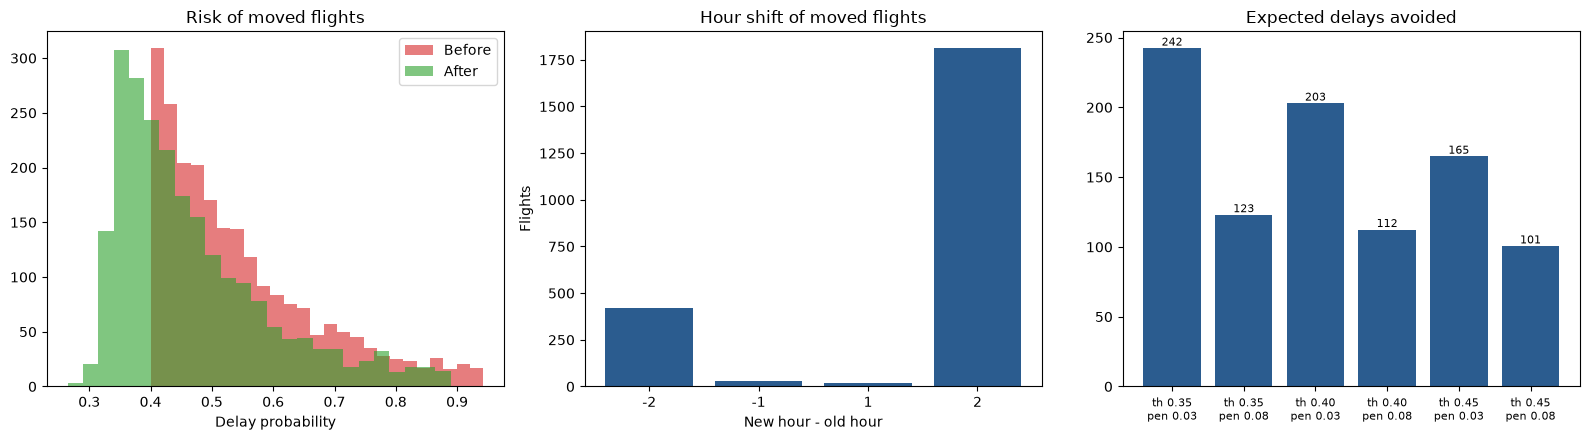

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

if len(moved_df) > 0:
    axes[0].hist(moved_df["orig_risk"], bins=25, alpha=0.6, label="Before", color="#d62728")
    axes[0].hist(moved_df["new_risk"], bins=25, alpha=0.6, label="After", color="#2ca02c")
    axes[0].set_title("Risk of moved flights")
    axes[0].set_xlabel("Delay probability")
    axes[0].legend()

    shift = (moved_df["new_hour"] - moved_df["orig_hour"]).value_counts().sort_index()
    axes[1].bar(shift.index.astype(str), shift.values, color="#2b5c8f")
    axes[1].set_title("Hour shift of moved flights")
    axes[1].set_xlabel("New hour - old hour")
    axes[1].set_ylabel("Flights")

labels = [f"th {r.threshold:.2f}\npen {r.penalty:.2f}" for r in sens_df.itertuples()]
bars = axes[2].bar(range(len(sens_df)), sens_df["delays_avoided"], color="#2b5c8f")
axes[2].set_xticks(range(len(sens_df)))
axes[2].set_xticklabels(labels, fontsize=8)
axes[2].set_title("Expected delays avoided")
axes[2].bar_label(bars, fmt="%.0f", fontsize=8)

plt.tight_layout()
plt.savefig(fig_dir / "phase2_rescheduling_summary.png", dpi=150)
plt.show()

## What we learned
- (We will write the real numbers here after the results are checked.)
- The simulation is only as good as its assumptions. The biggest weakness is that the model's "hour" effect is treated as cause and effect.
- The size of the benefit depends strongly on the risk threshold and the penalty (see the sensitivity table).
- This is an offline simulation for academic work. It is not an operational recommendation.